In [11]:
# Step I : Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# Step II : Load the Data
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

In [13]:
# Step III : Preprocessing
x_train = x_train.reshape(-1,784).astype('float32') / 255.0
x_test = x_test.reshape(-1,784).astype('float32') / 255.0

In [14]:
y_train = tf.keras.utils.to_categorical(y_train,10)
y_test = tf.keras.utils.to_categorical(y_test,10)

In [15]:
# Step IV : Model Configuration
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(64,activation='relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])

In [16]:
# Step V : Model Compilation
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [17]:
# Step VI : Training Phase
history = model.fit(x_train,y_train,
                    epochs=5,batch_size=64)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9165 - loss: 0.2848
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9663 - loss: 0.1127
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9766 - loss: 0.0769
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9811 - loss: 0.0597
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9849 - loss: 0.0480


In [18]:
# Step VII : Evaluate the Model
loss,accuracy = model.evaluate(x_test,y_test)
print("Loss:",loss)
print("Accuracy:",accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9711 - loss: 0.0950
Loss: 0.09498407691717148
Accuracy: 0.9710999727249146


In [19]:
# Step VIII : Tune Activation Function
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(64,activation='tanh'),
    tf.keras.layers.Dense(32,activation='tanh'),
    tf.keras.layers.Dense(10,activation='softmax')
])

In [20]:
model2.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

In [21]:
model2.fit(x_train,y_train,epochs=5,batch_size=64)

loss2,accuracy2 = model2.evaluate(x_test,y_test)
print("Tuned Accuracy:",accuracy2)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9042 - loss: 0.3575
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9503 - loss: 0.1696
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9645 - loss: 0.1211
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9722 - loss: 0.0931
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9771 - loss: 0.0752
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9674 - loss: 0.1075
Tuned Accuracy: 0.9674000144004822


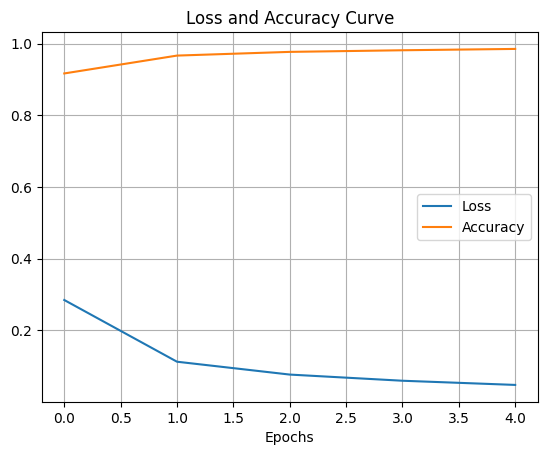

In [22]:
# Step IX : Plot Loss and Accuracy Curves
plt.plot(history.history['loss'],label='Loss')
plt.plot(history.history['accuracy'],label='Accuracy')
plt.xlabel("Epochs")
plt.title("Loss and Accuracy Curve")
plt.legend()
plt.grid()
plt.show()
